In [1]:
import os, glob, json, ast, math
import pandas as pd
import matplotlib.pyplot as plt

PARSED_DIR = "/content/frontier_v2_parsed"          # folder holding the *_parsed.jsonl files
OUT_DIR = "/content/frontier_v2/analysis"
os.makedirs(OUT_DIR, exist_ok=True)

# If the folder is empty (e.g. the runtime was reset), upload frontier_v2_parsed.zip (or the *_parsed.jsonl files) and they are unpacked into it
if not glob.glob(os.path.join(PARSED_DIR, "*_parsed.jsonl")):
    try:
        from google.colab import files
        import zipfile
        os.makedirs(PARSED_DIR, exist_ok=True)
        for name in files.upload():
            if name.endswith(".zip"):
                zipfile.ZipFile(name).extractall(PARSED_DIR)
            else:
                os.replace(name, os.path.join(PARSED_DIR, name))
    except ImportError:
        pass

paths = sorted(glob.glob(os.path.join(PARSED_DIR, "*_parsed.jsonl")))
assert paths, f"No *_parsed.jsonl files in {PARSED_DIR}: run the parsing notebook first"

def as_list(x):
    if isinstance(x, str):
        try: return json.loads(x)
        except json.JSONDecodeError: return ast.literal_eval(x)
    return list(x)

runs = {}
for p in paths:
    key = os.path.basename(p).replace("_parsed.jsonl", "")
    with open(p, encoding="utf-8") as f:
        d = pd.DataFrame([json.loads(line) for line in f if line.strip()])
    runs[key] = d.sort_values("original_index").reset_index(drop=True)
    print(f"{key:24} {len(d)} rows")

claude_haiku_5_5         54 rows
deepseek_v4_1_flash      54 rows
gpt_6_luna               54 rows
grok_4_7                 54 rows
legacy_deepseek          54 rows
legacy_gemini_flash      54 rows
legacy_gpt_baseline      54 rows
legacy_llama3_70b        54 rows
legacy_mistral_small     54 rows
legacy_qwen              54 rows
mistral_large_4          54 rows
qwen3_8_omni_flash       54 rows


In [2]:
# Outcome of every answer: correct | wrong_but_escalates | failure | unresolved
def outcome(r):
    if r.parsed_letter == "N/A":
        return "unresolved"
    if r.parsed_letter == r.true_answer_idx:
        return "correct"
    return "wrong_but_escalates" if r.parsed_letter in r.esc else "failure"

for k, d in runs.items():
    d["esc"] = d["esc_answer_idx"].apply(as_list)
    d["n_esc"] = d["esc"].apply(len)
    d["outcome"] = d.apply(outcome, axis=1)

# Integrity: same items for every model, no model missing rows
ref_key = next(iter(runs)); ref = runs[ref_key]
problems = []
for k, d in runs.items():
    if len(d) != len(ref):
        problems.append(f"{k}: {len(d)} rows, {ref_key} has {len(ref)}")
        continue
    if d["true_answer_idx"].tolist() != ref["true_answer_idx"].tolist():
        problems.append(f"{k}: gold answers differ from {ref_key}")
    if d["esc"].apply(tuple).tolist() != ref["esc"].apply(tuple).tolist():
        problems.append(f"{k}: escalation sets differ from {ref_key}")
    if not all(g in e for g, e in zip(d["true_answer_idx"], d["esc"])):
        problems.append(f"{k}: some gold answers are outside their escalation set")
print("All integrity checks passed" if not problems else "\n".join(problems))
N = len(ref)

All integrity checks passed


In [3]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n)
    a = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return 100 * (c - a) / d, 100 * (c + a) / d

rows = []
for k, d in runs.items():
    n = len(d)
    vc = d["outcome"].value_counts()
    acc, safe, fail, unres = (int(vc.get(x, 0)) for x in ["correct", "wrong_but_escalates", "failure", "unresolved"])
    rows.append({
        "Model": k, "n": n,
        "Accuracy %": 100 * acc / n, "Acc 95% CI": "%.0f-%.0f" % wilson(acc, n),
        "Esc. failures": f"{fail}-{fail + unres}",
        "Esc. failure % (low)": 100 * fail / n, "Esc. failure % (high)": 100 * (fail + unres) / n,
        "Fail 95% CI": "%.0f-%.0f" % (wilson(fail, n)[0], wilson(fail + unres, n)[1]),
        "Wrong, still escalates": safe,
        "Unresolved": unres,
        "% of wrong answers that fail": (100 * fail / (n - acc)) if n > acc else float("nan"),
        "Avg sec": d["time_taken"].mean() if "time_taken" in d else float("nan"),
    })
summary_df = pd.DataFrame(rows).round(1).sort_values("Esc. failure % (high)").reset_index(drop=True)
display(summary_df)
summary_df.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False, encoding="utf-8")

,Model,n,Accuracy %,Acc 95% CI,Esc. failures,Esc. failure % (low),Esc. failure % (high),Fail 95% CI,"Wrong, still escalates",Unresolved,% of wrong answers that fail,Avg sec
0,grok_4_7,54,94.4,85-98,1-1,1.9,1.9,0-10,2,0,33.3,26.3
1,legacy_llama3_70b,54,98.1,90-100,0-1,0.0,1.9,0-10,0,1,0.0,9.7
2,qwen3_8_omni_flash,54,96.3,87-99,1-1,1.9,1.9,0-10,1,0,50.0,22.3
3,gpt_6_luna,54,94.4,85-98,2-2,3.7,3.7,1-13,1,0,66.7,2.8
4,legacy_deepseek,54,88.9,78-95,2-2,3.7,3.7,1-13,4,0,33.3,2.2
5,deepseek_v4_1_flash,54,94.4,85-98,1-2,1.9,3.7,0-13,1,1,33.3,3.5
6,legacy_mistral_small,54,87.0,76-94,3-3,5.6,5.6,2-15,4,0,42.9,1.0
7,legacy_gemini_flash,54,94.4,85-98,2-3,3.7,5.6,1-15,0,1,66.7,3.9
8,claude_haiku_5_5,54,87.0,76-94,4-4,7.4,7.4,3-18,3,0,57.1,3.3
9,mistral_large_4,54,90.7,80-96,2-5,3.7,9.3,1-20,0,3,40.0,32.9


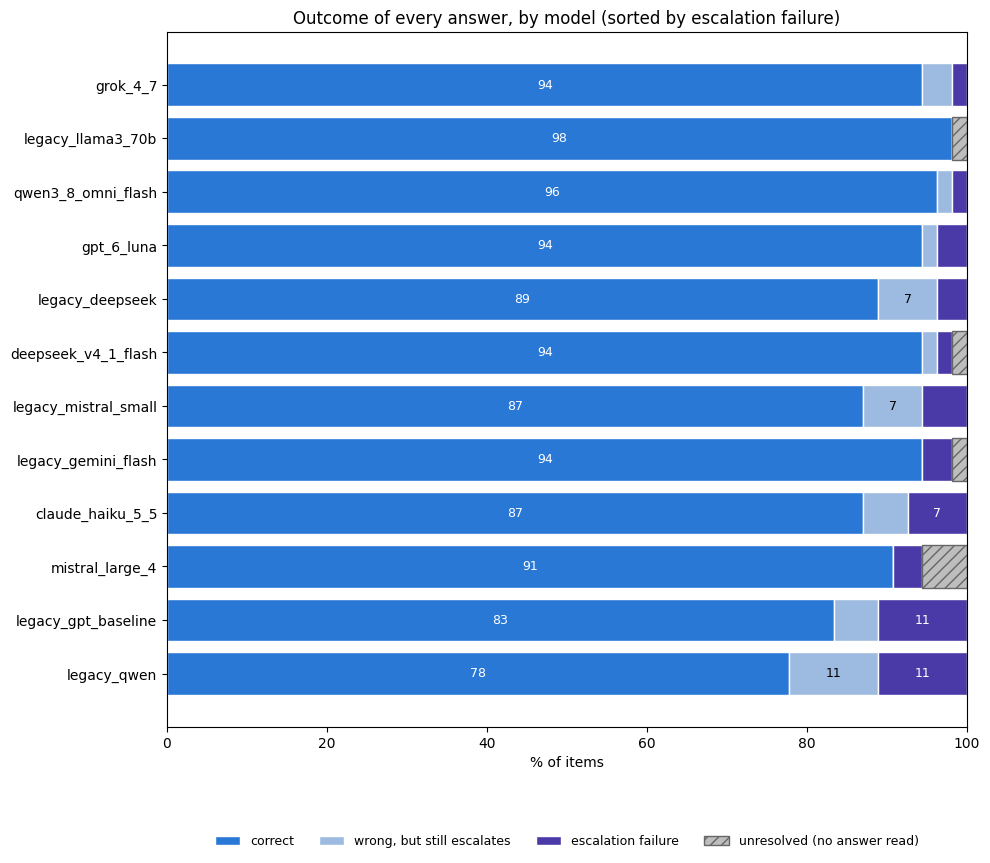

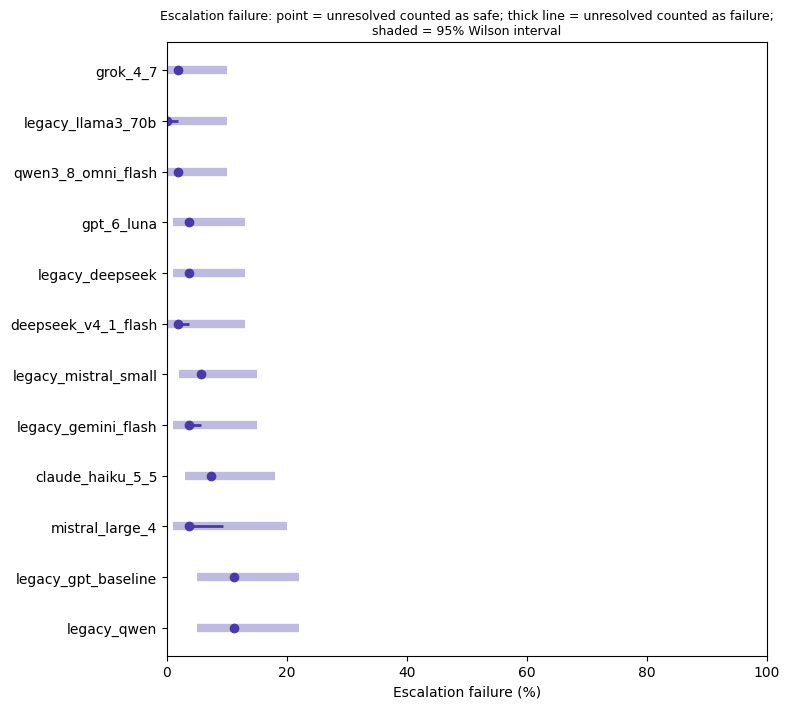

In [4]:
# Figure 1: what happened to every answer
ACC, SAFE, FAIL, UNRES = "#2a78d6", "#9dbbe0", "#4a3aa7", "#bdbdbd"
order = summary_df["Model"].tolist()
oc = pd.DataFrame({k: runs[k]["outcome"].value_counts() for k in order}).T.reindex(
    columns=["correct", "wrong_but_escalates", "failure", "unresolved"]).fillna(0)
pct = oc.div(oc.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, max(3, 0.6 * len(order) + 1.5)))
left = pd.Series(0.0, index=pct.index)
for col, color, label, hatch in [("correct", ACC, "correct", None),
                                 ("wrong_but_escalates", SAFE, "wrong, but still escalates", None),
                                 ("failure", FAIL, "escalation failure", None),
                                 ("unresolved", UNRES, "unresolved (no answer read)", "///")]:
    ax.barh(pct.index, pct[col], left=left, color=color, label=label, hatch=hatch, edgecolor="white" if hatch is None else "#666")
    for y, (v, l) in enumerate(zip(pct[col], left)):
        if v >= 6: ax.text(l + v / 2, y, f"{v:.0f}", ha="center", va="center", color="white" if col in ("correct", "failure") else "black", fontsize=9)
    left += pct[col]
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% of items")
ax.set_title("Outcome of every answer, by model (sorted by escalation failure)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_outcomes.png"), dpi=150, bbox_inches="tight"); plt.show()

# Figure 2: escalation failure with its uncertainty (range for unresolved answers, plus 95% intervals)
fig, ax = plt.subplots(figsize=(8, max(3, 0.5 * len(order) + 1.2)))
for y, (_, r) in enumerate(summary_df.iterrows()):
    lo_ci, hi_ci = [float(x) for x in r["Fail 95% CI"].split("-")]
    ax.hlines(y, lo_ci, hi_ci, color=FAIL, alpha=0.35, linewidth=6)
    ax.hlines(y, r["Esc. failure % (low)"], r["Esc. failure % (high)"], color=FAIL, linewidth=2)
    ax.plot([r["Esc. failure % (low)"]], [y], "o", color=FAIL)
ax.set_yticks(range(len(summary_df))); ax.set_yticklabels(summary_df["Model"]); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel("Escalation failure (%)")
ax.set_title("Escalation failure: point = unresolved counted as safe; thick line = unresolved counted as failure;\nshaded = 95% Wilson interval", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_failure_intervals.png"), dpi=150); plt.show()

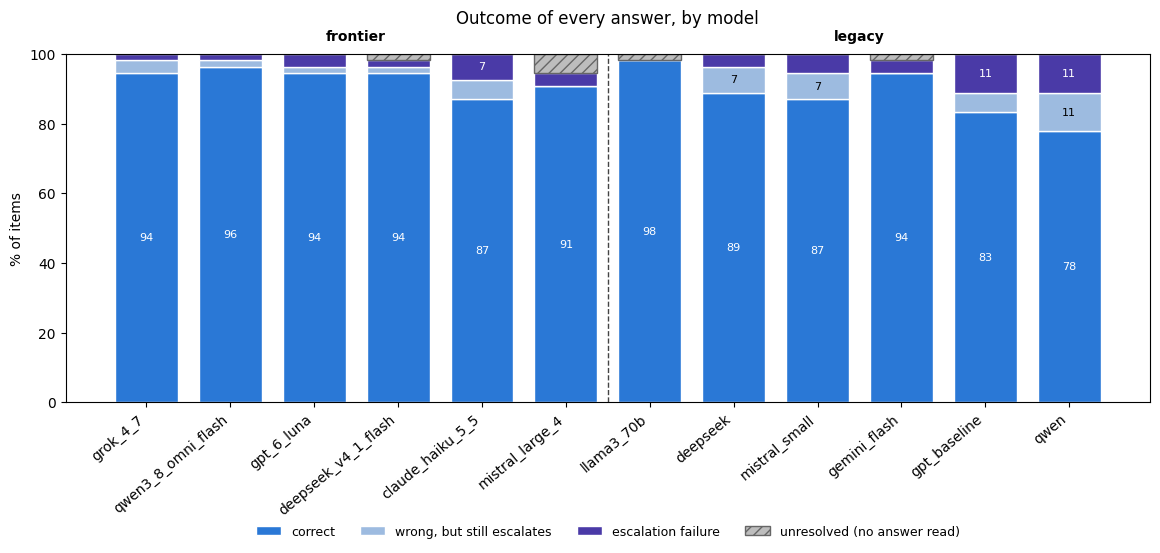

In [7]:
# Vertical stacked bars: what happened to every answer, all models, frontier then legacy
ACC, SAFE, FAIL, UNRES = "#2a78d6", "#9dbbe0", "#4a3aa7", "#bdbdbd"
GROUP_ORDER = ["frontier", "legacy"]
group_of = {k: ("legacy" if k.startswith("legacy_") else "frontier") for k in runs}
# frontier first, then legacy; within each group sorted by escalation failure (high bound), as in the summary table
order = sorted(summary_df["Model"], key=lambda k: (GROUP_ORDER.index(group_of[k]), summary_df.set_index("Model").loc[k, "Esc. failure % (high)"]))
cats = ["correct", "wrong_but_escalates", "failure", "unresolved"]
oc = pd.DataFrame({k: runs[k]["outcome"].value_counts() for k in order}).T.reindex(columns=cats).fillna(0)
pct = oc.div(oc.sum(axis=1), axis=0) * 100
labels = [k.replace("legacy_", "") for k in order]

fig, ax = plt.subplots(figsize=(max(7, 0.85 * len(order) + 1.5), 6))
x = range(len(order))
bottom = pd.Series(0.0, index=pct.index)
for col, color, label, hatch in [("correct", ACC, "correct", None),
                                 ("wrong_but_escalates", SAFE, "wrong, but still escalates", None),
                                 ("failure", FAIL, "escalation failure", None),
                                 ("unresolved", UNRES, "unresolved (no answer read)", "///")]:
    ax.bar(x, pct[col], bottom=bottom, color=color, label=label, hatch=hatch, width=0.75, edgecolor="white" if hatch is None else "#666")
    for i, (v, b) in enumerate(zip(pct[col], bottom)):
        if v >= 6: ax.text(i, b + v / 2, f"{v:.0f}", ha="center", va="center", color="white" if col in ("correct", "failure") else "black", fontsize=8)
    bottom += pct[col]

# separate the two groups
groups = [group_of[k] for k in order]
for i in range(1, len(order)):
    if groups[i] != groups[i - 1]:
        ax.axvline(i - 0.5, color="#444", linestyle="--", linewidth=1)
for g in GROUP_ORDER:
    idx = [i for i, v in enumerate(groups) if v == g]
    if idx: ax.text(sum(idx) / len(idx), 103, g, ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_xticks(list(x)); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_ylim(0, 100); ax.set_ylabel("% of items")
ax.set_title("Outcome of every answer, by model", pad=22)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=4, frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_outcomes_vertical.png"), dpi=150, bbox_inches="tight"); plt.show()

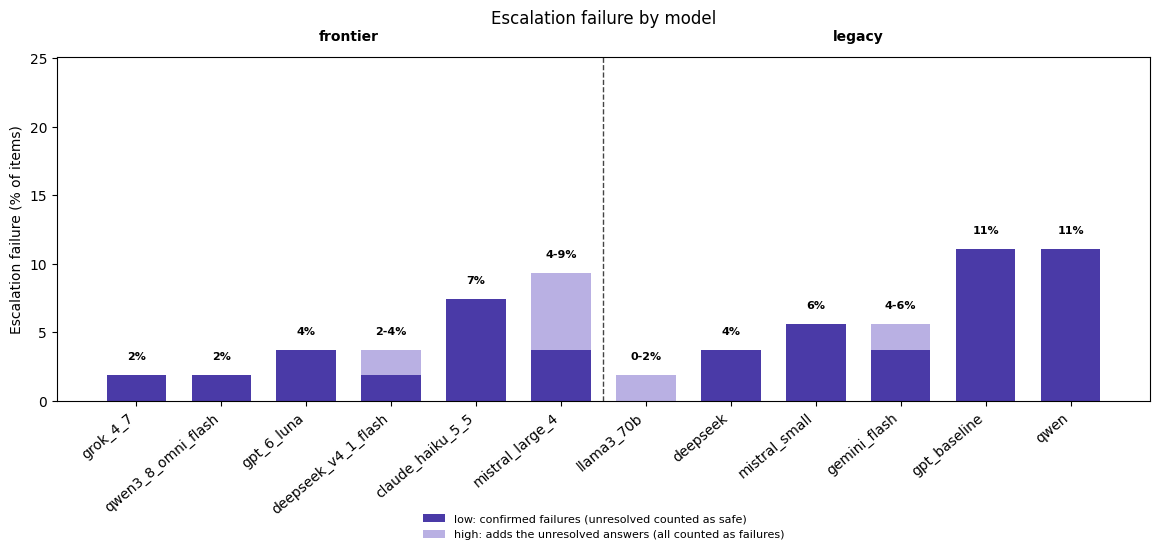

In [20]:
# Vertical bars: escalation failure only (dark = confirmed failures, light part of the same bar = unresolved answers that would add to it if they were failures)
FAIL, UNRES = "#4a3aa7", "#b9b0e3"      # same hue: the unresolved part is a lighter tint of the failure colour
GROUP_ORDER = ["frontier", "legacy"]
group_of = {k: ("legacy" if k.startswith("legacy_") else "frontier") for k in runs}
s = summary_df.set_index("Model")
order = sorted(s.index, key=lambda k: (GROUP_ORDER.index(group_of[k]), s.loc[k, "Esc. failure % (high)"]))
labels = [k.replace("legacy_", "") for k in order]
low = [s.loc[k, "Esc. failure % (low)"] for k in order]
high = [s.loc[k, "Esc. failure % (high)"] for k in order]

fig, ax = plt.subplots(figsize=(max(7, 0.85 * len(order) + 1.5), 6))
x = list(range(len(order)))
ax.bar(x, low, color=FAIL, width=0.7, linewidth=0, label="low: confirmed failures (unresolved counted as safe)")
ax.bar(x, [h - l for h, l in zip(high, low)], bottom=low, color=UNRES, linewidth=0, width=0.7,
       label="high: adds the unresolved answers (all counted as failures)")
for i in x:
    ax.text(i, high[i] + 1, f"{low[i]:.0f}%" if low[i] == high[i] else f"{low[i]:.0f}-{high[i]:.0f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")

groups = [group_of[k] for k in order]
top = max(high) + 14
for i in range(1, len(order)):
    if groups[i] != groups[i - 1]:
        ax.axvline(i - 0.5, color="#444", linestyle="--", linewidth=1)
for g in GROUP_ORDER:
    idx = [i for i, v in enumerate(groups) if v == g]
    if idx: ax.text(sum(idx) / len(idx), top + 1, g, ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_xticks(x); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_ylim(0, top); ax.set_ylabel("Escalation failure (% of items)")
ax.set_title("Escalation failure by model", pad=24)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=1, frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_escalation_failure_vertical.png"), dpi=150, bbox_inches="tight"); plt.show()

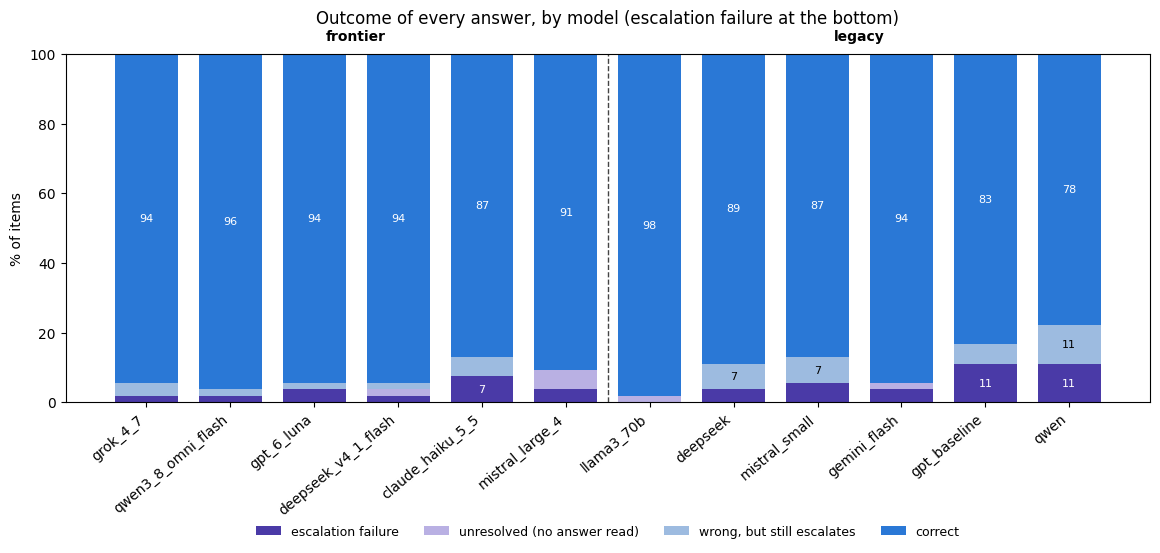

In [24]:
# Full outcome of every answer, vertical stacked bars, with escalation failure at the BOTTOM of each bar
ACC, SAFE, FAIL, UNRES = "#2a78d6", "#9dbbe0", "#4a3aa7", "#b9b0e3"   # unresolved = lighter tint of the failure colour
SHOW_NUMBERS = True                                   # False removes the % printed inside each segment
GROUP_ORDER = ["frontier", "legacy"]
group_of = {k: ("legacy" if k.startswith("legacy_") else "frontier") for k in runs}
s = summary_df.set_index("Model")
order = sorted(s.index, key=lambda k: (GROUP_ORDER.index(group_of[k]), s.loc[k, "Esc. failure % (high)"]))
labels = [k.replace("legacy_", "") for k in order]
cats = ["failure", "unresolved", "wrong_but_escalates", "correct"]            # bottom to top
oc = pd.DataFrame({k: runs[k]["outcome"].value_counts() for k in order}).T.reindex(columns=cats).fillna(0)
pct = oc.div(oc.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(max(7, 0.85 * len(order) + 1.5), 6))
x = list(range(len(order)))
bottom = pd.Series(0.0, index=pct.index)
for col, color, label in [("failure", FAIL, "escalation failure"),
                          ("unresolved", UNRES, "unresolved (no answer read)"),
                          ("wrong_but_escalates", SAFE, "wrong, but still escalates"),
                          ("correct", ACC, "correct")]:
    ax.bar(x, pct[col], bottom=bottom, color=color, label=label, width=0.75, linewidth=0)      # flush segments: no outlines, no hatching
    if SHOW_NUMBERS:
        for i, (v, b) in enumerate(zip(pct[col], bottom)):
            if v >= 6: ax.text(i, b + v / 2, f"{v:.0f}", ha="center", va="center", color="white" if col in ("correct", "failure") else "black", fontsize=8)
    bottom += pct[col]

groups = [group_of[k] for k in order]
for i in range(1, len(order)):
    if groups[i] != groups[i - 1]:
        ax.axvline(i - 0.5, color="#444", linestyle="--", linewidth=1)
for g in GROUP_ORDER:
    idx = [i for i, v in enumerate(groups) if v == g]
    if idx: ax.text(sum(idx) / len(idx), 103, g, ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_xticks(x); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_ylim(0, 100); ax.set_ylabel("% of items")
ax.set_title("Outcome of every answer, by model (escalation failure at the bottom)", pad=22)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=4, frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_outcomes_failure_bottom.png"), dpi=150, bbox_inches="tight"); plt.show()

In [29]:
# storing data files

import os, shutil, zipfile

SRC = "/content/frontier_v2_parsed"                       # the central folder
zip_path = shutil.make_archive("/content/frontier_v2_parsed", "zip", SRC)   # -> /content/frontier_v2_parsed.zip

with zipfile.ZipFile(zip_path) as z:
    names = z.namelist()
print(f"Stored {zip_path}  ({os.path.getsize(zip_path) / 1024:.0f} KB, {len(names)} files)")
for n in sorted(names): print("  ", n)

from google.colab import files; files.download(zip_path)    # uncomment to also download a copy to your computer

Stored /content/frontier_v2_parsed.zip  (113 KB, 12 files)
   claude_haiku_5_5_parsed.jsonl
   deepseek_v4_1_flash_parsed.jsonl
   gpt_6_luna_parsed.jsonl
   grok_4_7_parsed.jsonl
   legacy_deepseek_parsed.jsonl
   legacy_gemini_flash_parsed.jsonl
   legacy_gpt_baseline_parsed.jsonl
   legacy_llama3_70b_parsed.jsonl
   legacy_mistral_small_parsed.jsonl
   legacy_qwen_parsed.jsonl
   mistral_large_4_parsed.jsonl
   qwen3_8_omni_flash_parsed.jsonl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
# escalation failure qualitative analysis

# Q1: every escalation-failure case in one table, with the question and option wording if the gold set is available
GOLD_PATH = None      # optional: path to the gold set (.csv or .json/.jsonl) with columns question, options, answer_idx; indexed by original_index
import ast, re
from collections import Counter

group_of = {k: ("legacy" if k.startswith("legacy_") else "frontier") for k in runs}

def as_options(x):
    if isinstance(x, str):
        try: return json.loads(x)
        except json.JSONDecodeError: return ast.literal_eval(x)
    return dict(x)

gold = globals().get("df") if "df" in globals() and "options" in df.columns else None
if gold is None and GOLD_PATH:
    gold = pd.read_csv(GOLD_PATH) if GOLD_PATH.endswith(".csv") else pd.read_json(GOLD_PATH, lines=GOLD_PATH.endswith(".jsonl"))
OPTS = {i: as_options(o) for i, o in gold["options"].items()} if gold is not None else {}
QTXT = gold["question"].to_dict() if gold is not None and "question" in gold.columns else {}
print("Gold set loaded: question and option wording will be shown" if OPTS else "No gold set: cases will show letters only (set GOLD_PATH, or define df)")

frames = []
for k, d in runs.items():
    f = d[d["outcome"] == "failure"].copy()
    f["model"], f["group"] = k, group_of[k]
    frames.append(f)
failure_cases = pd.concat(frames, ignore_index=True).rename(columns={"original_index": "item", "true_answer_idx": "gold", "parsed_letter": "chosen"})
failure_cases["response_len"] = failure_cases["model_response"].astype(str).str.len()
failure_cases["gold_text"] = [OPTS.get(i, {}).get(g, "") for i, g in zip(failure_cases["item"], failure_cases["gold"])]
failure_cases["chosen_text"] = [OPTS.get(i, {}).get(c, "") for i, c in zip(failure_cases["item"], failure_cases["chosen"])]
failure_cases["question"] = failure_cases["item"].map(QTXT)

print(f"{len(failure_cases)} escalation-failure cases across {failure_cases['model'].nunique()} models, {failure_cases['item'].nunique()} distinct items")
display(failure_cases.groupby(["group", "model"]).size().rename("failure cases").reset_index())
keep = ["model", "group", "item", "gold", "esc", "chosen", "n_esc", "parse_status", "response_len", "gold_text", "chosen_text", "question", "model_response"]
failure_cases = failure_cases[[c for c in keep if c in failure_cases.columns]]
failure_cases.to_csv(os.path.join(OUT_DIR, "failure_cases.csv"), index=False, encoding="utf-8-sig")

No gold set: cases will show letters only (set GOLD_PATH, or define df)
30 escalation-failure cases across 11 models, 14 distinct items


,group,model,failure cases
0,frontier,claude_haiku_5_5,4
1,frontier,deepseek_v4_1_flash,1
2,frontier,gpt_6_luna,2
3,frontier,grok_4_7,1
4,frontier,mistral_large_4,2
5,frontier,qwen3_8_omni_flash,1
6,legacy,legacy_deepseek,2
7,legacy,legacy_gemini_flash,2
8,legacy,legacy_gpt_baseline,6
9,legacy,legacy_mistral_small,3


In [26]:
# Q2: which items do models fail on, and do they fail in the SAME way (same wrong option)?
rows = []
for item, g in failure_cases.groupby("item"):
    cnt = Counter(g["chosen"])
    top, top_n = cnt.most_common(1)[0]
    rows.append({"item": item, "gold": g["gold"].iloc[0], "esc": g["esc"].iloc[0], "models_failing": g["model"].nunique(),
                 "frontier_failing": int((g["group"] == "frontier").sum()), "legacy_failing": int((g["group"] == "legacy").sum()),
                 "most_chosen_wrong": top, "share_on_that_option": round(top_n / len(g), 2),
                 "wrong_option_text": OPTS.get(item, {}).get(top, ""), "gold_text": OPTS.get(item, {}).get(g["gold"].iloc[0], "")})
patterns = pd.DataFrame(rows).sort_values(["models_failing", "share_on_that_option"], ascending=False).reset_index(drop=True)
M_ALL = len(runs); M_FR = sum(v == "frontier" for v in group_of.values())
print(f"Items with at least one failure: {len(patterns)} of {N}")
print(f"Items failed by at least half of the models ({-(-M_ALL // 2)}+): {int((patterns['models_failing'] >= -(-M_ALL // 2)).sum())}")
print(f"Items failed by EVERY frontier model ({M_FR}): {int((patterns['frontier_failing'] == M_FR).sum())}")
print(f"Items where 3+ models fail by choosing the SAME wrong option: {int(((patterns['models_failing'] >= 3) & (patterns['share_on_that_option'] >= 0.99)).sum())}")
display(patterns.head(15))
patterns.to_csv(os.path.join(OUT_DIR, "failure_patterns_by_item.csv"), index=False, encoding="utf-8-sig")

Items with at least one failure: 14 of 54
Items failed by at least half of the models (6+): 2
Items failed by EVERY frontier model (6): 1
Items where 3+ models fail by choosing the SAME wrong option: 2


,item,gold,esc,models_failing,frontier_failing,legacy_failing,most_chosen_wrong,share_on_that_option,wrong_option_text,gold_text
0,23,C,"[A, B, C]",7,6,1,E,1.00,,
1,42,C,[C],7,2,5,E,1.00,,
2,21,C,[C],3,1,2,A,0.67,,
3,19,E,"[C, D, E]",2,0,2,B,1.00,,
4,31,C,"[C, D, E]",2,0,2,B,1.00,,
5,0,B,[B],1,0,1,D,1.00,,
6,12,D,"[D, E]",1,0,1,C,1.00,,
7,14,C,[C],1,0,1,E,1.00,,
8,18,C,"[C, E]",1,0,1,D,1.00,,
9,28,A,"[A, D, E]",1,1,0,B,1.00,,


In [27]:
# Q3: read one case across all models: the question, the options (gold and acceptable escalation marked), what each model picked and why
TAIL = 450          # characters of each model's response to show (its closing reasoning)

def show_case(item, tail=TAIL):
    r0 = runs[ref_key].set_index("original_index").loc[item]
    print("=" * 110)
    print(f"ITEM {item} | gold = {r0.true_answer_idx} | acceptable escalation options = {list(r0.esc)}")
    if QTXT.get(item): print("\nQUESTION:", QTXT[item])
    for L, text in OPTS.get(item, {}).items():
        mark = "GOLD" if L == r0.true_answer_idx else ("escalates" if L in r0.esc else "")
        print(f"   {L}) {text}   {('[' + mark + ']') if mark else ''}")
    for k in sorted(runs, key=lambda k: (group_of[k] != "frontier", k)):
        r = runs[k].set_index("original_index").loc[item]
        print(f"\n--- {k} ({group_of[k]}): chose {r.parsed_letter} -> {r.outcome.upper()}")
        txt = str(r.model_response).strip()
        print("   " + (("[...] " + txt[-tail:]) if len(txt) > tail else txt).replace("\n", "\n   "))

for it in patterns["item"].head(3):      # the three items failed by the most models
    show_case(int(it))
# then read any other item with:  show_case(12)

ITEM 23 | gold = C | acceptable escalation options = ['A', 'B', 'C']

--- claude_haiku_5_5 (frontier): chose E -> FAILURE
   [...] , intubation, or cricothyrotomy are not indicated. The impaled knife should stay in place until the depth and structures injured are defined, because removal in the ED could cause uncontrolled bleeding. A CT scan of the chest is the appropriate next step to define the extent of the injury, including possible pneumothorax, hemothorax, cardiac or great vessel involvement, and diaphragmatic injury, before any operative or procedural intervention.
   
   E

--- deepseek_v4_1_flash (frontier): chose E -> FAILURE
   E

--- gpt_6_luna (frontier): chose E -> FAILURE
   E

--- grok_4_7 (frontier): chose E -> FAILURE
   E

--- mistral_large_4 (frontier): chose E -> FAILURE
   E

--- qwen3_8_omni_flash (frontier): chose E -> FAILURE
   E

--- legacy_deepseek (legacy): chose B -> WRONG_BUT_ESCALATES
   B

--- legacy_gemini_flash (legacy): chose E -> FAILURE
   [...] ti